In [4]:
!pip install librosa

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
!wget -O /content/ravdess.zip "https://zenodo.org/records/1188976/files/Audio_Speech_Actors_01-24.zip?download=1"

--2026-10-25 04:20:52--  https://zenodo.org/records/1188976/files/Audio_Speech_Actors_01-24.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.40.132, 188.185.47.192, 188.185.42.113, ...
Connecting to zenodo.org (zenodo.org)|188.185.40.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 208468073 (199M) [application/octet-stream]
Saving to: ‘/content/ravdess.zip’

/content/ravdess.zi 100%[===================>] 198.81M  5.14MB/s    in 2m 25s  

2026-10-25 04:23:17 (1.37 MB/s) - ‘/content/ravdess.zip’ saved [208468073/208468073]



In [8]:
import zipfile
import os

zip_path = "/content/ravdess.zip"
extract_path = "/content/RAVDESS"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Files and folders:", os.listdir(extract_path)[:10])

Dataset extracted successfully!
Files and folders: ['Actor_09', 'Actor_16', 'Actor_11', 'Actor_02', 'Actor_06', 'Actor_03', 'Actor_12', 'Actor_05', 'Actor_22', 'Actor_10']


In [9]:
import os
import numpy as np
import librosa

DATA_PATH = "/content/RAVDESS"

features = []
labels = []

for root, dirs, files in os.walk(DATA_PATH):
    for file in files:
        if file.endswith(".wav"):
            parts = file.split("-")
            if len(parts) >= 3:
                emotion = int(parts[2])

                try:
                    path = os.path.join(root, file)
                    audio, sr = librosa.load(path, duration=3, res_type="kaiser_fast")
                    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=40)
                    features.append(np.mean(mfcc.T, axis=0))
                    labels.append(emotion)
                except Exception as e:
                    print("Skipped:", file)

X = np.array(features)
y = np.array(labels)

print("Feature extraction completed!")
print("Total audio files processed:", len(X))
print("Feature shape:", X.shape)
print("Labels shape:", y.shape)

Skipped: 03-01-02-01-01-01-09.wav
Skipped: 03-01-08-01-02-01-09.wav
Skipped: 03-01-06-02-01-02-09.wav
Skipped: 03-01-07-02-01-02-09.wav
Skipped: 03-01-07-01-01-02-09.wav
Skipped: 03-01-02-01-02-02-09.wav
Skipped: 03-01-08-02-02-02-09.wav
Skipped: 03-01-04-02-01-02-09.wav
Skipped: 03-01-02-01-01-02-09.wav
Skipped: 03-01-06-01-01-01-09.wav
Skipped: 03-01-08-01-01-01-09.wav
Skipped: 03-01-02-02-02-01-09.wav
Skipped: 03-01-07-02-02-02-09.wav
Skipped: 03-01-03-01-01-02-09.wav
Skipped: 03-01-01-01-02-01-09.wav
Skipped: 03-01-06-01-02-01-09.wav
Skipped: 03-01-07-01-02-02-09.wav
Skipped: 03-01-08-02-01-01-09.wav
Skipped: 03-01-01-01-01-01-09.wav
Skipped: 03-01-02-02-02-02-09.wav
Skipped: 03-01-03-01-01-01-09.wav
Skipped: 03-01-03-02-02-01-09.wav
Skipped: 03-01-07-02-01-01-09.wav
Skipped: 03-01-05-02-02-01-09.wav
Skipped: 03-01-05-02-01-01-09.wav
Skipped: 03-01-08-02-01-02-09.wav
Skipped: 03-01-04-01-02-01-09.wav
Skipped: 03-01-05-02-01-02-09.wav
Skipped: 03-01-07-01-01-01-09.wav
Skipped: 03-01

In [11]:
import os

DATA_PATH = "/content/RAVDESS"

print("Dataset folder exists:", os.path.exists(DATA_PATH))

for root, dirs, files in os.walk(DATA_PATH):
    wav_files = [f for f in files if f.endswith(".wav")]
    if wav_files:
        print("Audio folder:", root)
        print("Audio files found:", len(wav_files))
        print("Example:", wav_files[0])
        break
else:
    print("No WAV files found!")

Dataset folder exists: True
Audio folder: /content/RAVDESS/Actor_09
Audio files found: 60
Example: 03-01-02-01-01-01-09.wav


In [12]:
import os
import numpy as np
import librosa

DATA_PATH = "/content/ravdess"

features = []
labels = []

for root, dirs, files in os.walk(DATA_PATH):
    for file in files:
        if file.endswith(".wav"):
            parts = file.split("-")
            if len(parts) >= 3:
                emotion = int(parts[2])

                try:
                    path = os.path.join(root, file)
                    audio, sr = librosa.load(
                        path, duration=3, res_type="kaiser_fast"
                    )
                    mfcc = librosa.feature.mfcc(
                        y=audio, sr=sr, n_mfcc=40
                    )
                    features.append(np.mean(mfcc.T, axis=0))
                    labels.append(emotion)
                except Exception as e:
                    print("Skipped:", file, e)

X = np.array(features)
y = np.array(labels)

print("Feature extraction completed!")
print("Total audio files processed:", len(X))
print("Features shape:", X.shape)

Feature extraction completed!
Total audio files processed: 0
Features shape: (0,)


In [15]:
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Dataset path exists:", os.path.exists("/content/ravdess"))

for root, dirs, files in os.walk("/content/ravdess"):
    wav_files = [f for f in files if f.lower().endswith(".wav")]
    if wav_files:
        print("Audio folder:", root)
        print("Number of audio files:", len(wav_files))
        print("First file:", wav_files[0])
        break

X shape: (0,)
y shape: (0,)
Dataset path exists: False


In [16]:
import os
import zipfile
import urllib.request

zip_path = "/content/ravdess.zip"
extract_path = "/content/ravdess"

url = "https://zenodo.org/records/1188976/files/Audio_Speech_Actors_01-24.zip?download=1"

if not os.path.exists(zip_path):
    print("Downloading dataset...")
    urllib.request.urlretrieve(url, zip_path)

print("Extracting dataset...")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted!")

for root, dirs, files in os.walk(extract_path):
    wav_files = [f for f in files if f.lower().endswith(".wav")]
    if wav_files:
        print("Audio files found:", len(wav_files))
        print("Folder:", root)
        break

Extracting dataset...
Dataset extracted!
Audio files found: 60
Folder: /content/ravdess/Actor_09


In [17]:
import os
import numpy as np
import librosa

DATA_PATH = "/content/ravdess"

features = []
labels = []

for root, dirs, files in os.walk(DATA_PATH):
    for file in files:
        if file.lower().endswith(".wav"):
            parts = file.split("-")

            if len(parts) >= 3:
                emotion = int(parts[2])

                try:
                    path = os.path.join(root, file)
                    audio, sr = librosa.load(path, duration=3)
                    mfcc = librosa.feature.mfcc(
                        y=audio, sr=sr, n_mfcc=40
                    )
                    features.append(np.mean(mfcc.T, axis=0))
                    labels.append(emotion)
                except Exception as e:
                    print("Skipped:", file, e)

X = np.array(features)
y = np.array(labels)

print("Feature extraction completed!")
print("Total audio files processed:", len(X))
print("X shape:", X.shape)
print("y shape:", y.shape)

Feature extraction completed!
Total audio files processed: 1440
X shape: (1440, 40)
y shape: (1440,)


In [18]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = SVC(kernel="rbf", class_weight="balanced")
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model trained successfully!")
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print(classification_report(y_test, y_pred, zero_division=0))

Model trained successfully!
Accuracy: 59.72 %
              precision    recall  f1-score   support

           1       0.33      0.67      0.44        15
           2       0.63      0.92      0.75        37
           3       0.52      0.33      0.41        42
           4       0.56      0.36      0.44        39
           5       0.85      0.69      0.76        51
           6       0.61      0.73      0.67        37
           7       0.57      0.39      0.46        33
           8       0.57      0.74      0.64        34

    accuracy                           0.60       288
   macro avg       0.58      0.60      0.57       288
weighted avg       0.61      0.60      0.59       288



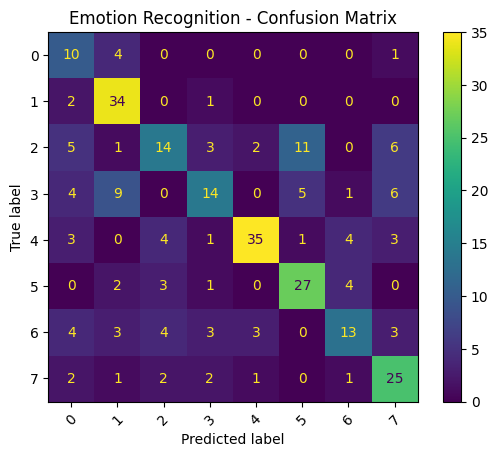

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(xticks_rotation=45)

plt.title("Emotion Recognition - Confusion Matrix")
plt.show()

In [20]:
emotion_labels = {
    1: "Neutral",
    2: "Calm",
    3: "Happy",
    4: "Sad",
    5: "Angry",
    6: "Fearful",
    7: "Disgust",
    8: "Surprised"
}

print("Emotion Recognition Model Results")
print("-" * 35)

for actual, predicted in zip(y_test[:10], y_pred[:10]):
    print(
        "Actual Emotion:", emotion_labels.get(actual, "Unknown"),
        "| Predicted Emotion:", emotion_labels.get(predicted, "Unknown")
    )

Emotion Recognition Model Results
-----------------------------------
Actual Emotion: Angry | Predicted Emotion: Angry
Actual Emotion: Happy | Predicted Emotion: Neutral
Actual Emotion: Sad | Predicted Emotion: Sad
Actual Emotion: Fearful | Predicted Emotion: Fearful
Actual Emotion: Fearful | Predicted Emotion: Calm
Actual Emotion: Sad | Predicted Emotion: Sad
Actual Emotion: Fearful | Predicted Emotion: Fearful
Actual Emotion: Happy | Predicted Emotion: Neutral
Actual Emotion: Angry | Predicted Emotion: Angry
Actual Emotion: Calm | Predicted Emotion: Calm
